In [3]:
import pandas as pd

data = {
    "customer_id": [f"C{i:02d}" for i in range(1, 31)],
    "age": 
[22,24,25,23,27,29,31,33,35,36,38,40,42,44,46,48,50,52,54,56,28,30,34,37,41,43,47,49,53,58],
    "annual_income": 
[28000,30000,32000,29000,35000,38000,42000,45000,48000,51000,54000,58000,62000,68000,72000,76000,82000,88000,92000,98000,36000,40000,47000,53000,61000,66000,74000,80000,90000,105000],
    "spending_score": 
[82,78,85,80,75,72,69,65,63,60,58,55,52,48,45,42,38,35,30,25,77,70,64,57,50,46,40,36,28,20],
    "visits_per_month": [10,9,11,10,8,8,7,7,6,6,5,5,5,4,4,4,3,3,2,2,9,8,7,6,5,4,4,3,2,1],
    "avg_order_value": 
[1200,1350,1100,1250,1400,1500,1600,1700,1800,1900,2100,2200,2400,2600,2800,3000,3300,3500,3800
,4200,1450,1550,1750,2050,2350,2700,3100,3400,3900,4500],
    "membership_months": 
[4,6,5,7,8,9,10,12,14,16,18,20,22,24,26,28,30,32,34,36,7,9,13,17,21,25,29,31,35,40],
    "city": 
["Kochi","Calicut","Kochi","Thrissur","Calicut","Kochi","Thrissur","Calicut","Kochi","Thrissur"
] * 3,
    "churn": [0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,0,0,0,0,0,1,1,1,1,1]
}
df = pd.DataFrame(data)
print(df.head())

  customer_id  age  annual_income  spending_score  visits_per_month  \
0         C01   22          28000              82                10   
1         C02   24          30000              78                 9   
2         C03   25          32000              85                11   
3         C04   23          29000              80                10   
4         C05   27          35000              75                 8   

   avg_order_value  membership_months      city  churn  
0             1200                  4     Kochi      0  
1             1350                  6   Calicut      0  
2             1100                  5     Kochi      0  
3             1250                  7  Thrissur      0  
4             1400                  8   Calicut      0  


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   customer_id        30 non-null     str  
 1   age                30 non-null     int64
 2   annual_income      30 non-null     int64
 3   spending_score     30 non-null     int64
 4   visits_per_month   30 non-null     int64
 5   avg_order_value    30 non-null     int64
 6   membership_months  30 non-null     int64
 7   city               30 non-null     str  
 8   churn              30 non-null     int64
dtypes: int64(7), str(2)
memory usage: 2.2 KB


In [8]:
df["estimated_monthly_value"] = df["visits_per_month"]*df["avg_order_value"]
df['loyalty_score'] = df["membership_months"]* df["visits_per_month"]
print(df[["customer_id", "estimated_monthly_value", "loyalty_score"]].head)

<bound method NDFrame.head of    customer_id  estimated_monthly_value  loyalty_score
0          C01                    12000             40
1          C02                    12150             54
2          C03                    12100             55
3          C04                    12500             70
4          C05                    11200             64
5          C06                    12000             72
6          C07                    11200             70
7          C08                    11900             84
8          C09                    10800             84
9          C10                    11400             96
10         C11                    10500             90
11         C12                    11000            100
12         C13                    12000            110
13         C14                    10400             96
14         C15                    11200            104
15         C16                    12000            112
16         C17                     

In [9]:
df_encoded = pd.get_dummies(df, columns=["city"], dtype=int)
df_encoded.filter(like='city_').head()

,city_Calicut,city_Kochi,city_Thrissur
0,0,1,0
1,1,0,0
2,0,1,0
3,0,0,1
4,1,0,0


In [11]:
from sklearn.preprocessing import StandardScaler
features = ['annual_income', 'spending_score', 'visits_per_month', 'avg_order_value']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

Text(0.5, 1.0, 'Elbow Method')

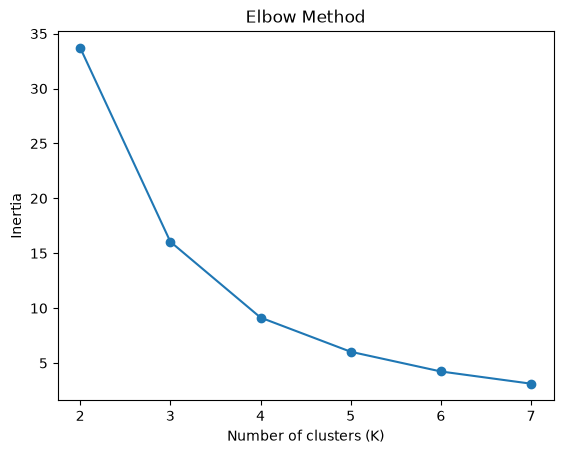

In [14]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
inertias=[]
sil_scores = []

for k in range(2, 8):
    km=KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels= km.fit_predict(X_scaled)
    
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, cluster_labels))
plt.plot(range(2, 8), inertias, marker='o')
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")


Text(0.5, 1.0, 'Calculation')

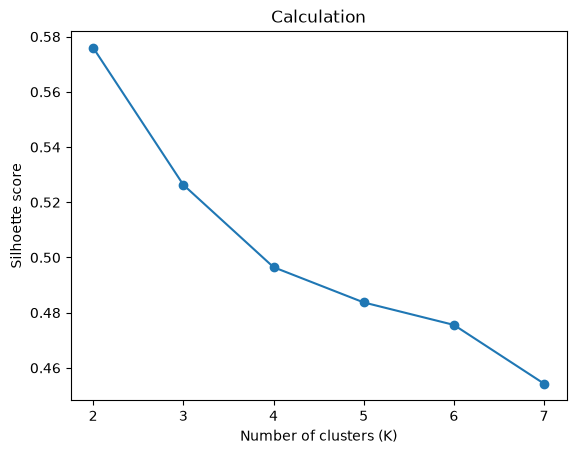

In [15]:
plt.plot(range(2, 8), sil_scores, marker='o')
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhoette score")
plt.title("Calculation")

In [21]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X_scaled)
print(df[["customer_id", "cluster"]].head(20))

   customer_id  cluster
0          C01        1
1          C02        1
2          C03        1
3          C04        1
4          C05        1
5          C06        1
6          C07        1
7          C08        1
8          C09        1
9          C10        1
10         C11        1
11         C12        1
12         C13        0
13         C14        0
14         C15        0
15         C16        0
16         C17        0
17         C18        0
18         C19        0
19         C20        0


In [23]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(n_clusters=3, linkage="ward")
df["hier_cluster"] = hc.fit_predict(X_scaled)
print(df[["customer_id", "hier_cluster"]].head(10))

  customer_id  hier_cluster
0         C01             2
1         C02             2
2         C03             2
3         C04             2
4         C05             2
5         C06             2
6         C07             1
7         C08             1
8         C09             1
9         C10             1


{'icoord': [[25.0, 25.0, 35.0, 35.0],
  [15.0, 15.0, 30.0, 30.0],
  [5.0, 5.0, 22.5, 22.5],
  [55.0, 55.0, 65.0, 65.0],
  [45.0, 45.0, 60.0, 60.0],
  [75.0, 75.0, 85.0, 85.0],
  [105.0, 105.0, 115.0, 115.0],
  [95.0, 95.0, 110.0, 110.0],
  [80.0, 80.0, 102.5, 102.5],
  [52.5, 52.5, 91.25, 91.25],
  [13.75, 13.75, 71.875, 71.875],
  [135.0, 135.0, 145.0, 145.0],
  [125.0, 125.0, 140.0, 140.0],
  [155.0, 155.0, 165.0, 165.0],
  [185.0, 185.0, 195.0, 195.0],
  [175.0, 175.0, 190.0, 190.0],
  [160.0, 160.0, 182.5, 182.5],
  [132.5, 132.5, 171.25, 171.25],
  [205.0, 205.0, 215.0, 215.0],
  [225.0, 225.0, 235.0, 235.0],
  [210.0, 210.0, 230.0, 230.0],
  [255.0, 255.0, 265.0, 265.0],
  [245.0, 245.0, 260.0, 260.0],
  [285.0, 285.0, 295.0, 295.0],
  [275.0, 275.0, 290.0, 290.0],
  [252.5, 252.5, 282.5, 282.5],
  [220.0, 220.0, 267.5, 267.5],
  [151.875, 151.875, 243.75, 243.75],
  [42.8125, 42.8125, 197.8125, 197.8125]],
 'dcoord': [[0.0,
   np.float64(0.17715969445273078),
   np.float64(0.177

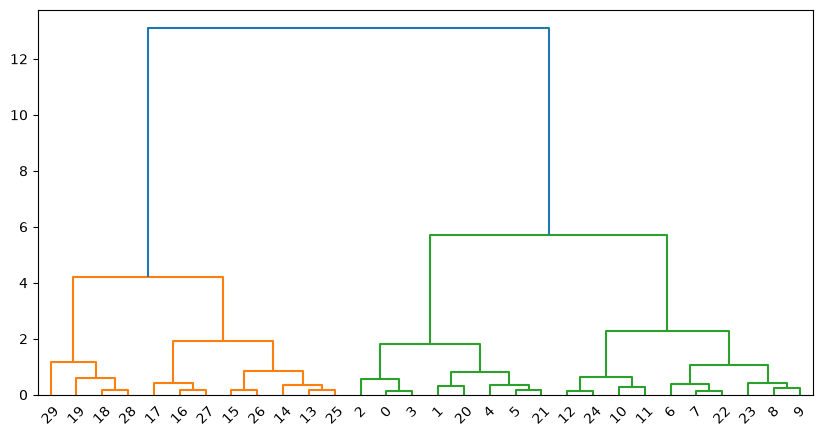

In [24]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z= linkage(X_scaled, method='ward')
plt.figure(figsize=(10, 5))

dendrogram(Z)

In [25]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
pca.explained_variance_ratio_


array([0.98362296, 0.01406875])

In [26]:
pca.explained_variance_ratio_.sum()

np.float64(0.9976917162596024)